In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [41]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")
print(df.head())

      lead_source       industry employment_status       location  \
0  organic_search     technology          employed         europe   
1    social_media     technology          employed  south_america   
2        referral         retail          employed         europe   
3        paid_ads  manufacturing           student            NaN   
4        referral  manufacturing           student  north_america   

   annual_income  number_of_courses_viewed  interaction_count  lead_score  \
0        88160.0                         3                  4        0.64   
1        72688.0                         3                  7        0.72   
2        44697.0                         3                  4        0.58   
3            NaN                         3                  6        0.57   
4        24062.0                         4                  5        0.62   

   converted  
0          1  
1          1  
2          1  
3          0  
4          1  


In [42]:

categorical_features = list(df.dtypes[df.dtypes == "str"].index)
numerical_features = list(df.dtypes[df.dtypes != "str"].index)
y = df["converted"].values
numerical_features.remove("converted")


df[categorical_features] = df[categorical_features].fillna("NA")
df[numerical_features] = df[numerical_features].fillna(0)

print(df.isnull().sum())

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


In [43]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)



In [44]:
y_train = df_train["converted"].values
del df_train["converted"]

y_test = df_test["converted"].values
del df_test["converted"]

y_val = df_val["converted"].values
del df_val["converted"]


In [45]:
from sklearn.metrics import roc_auc_score, auc
for feature in numerical_features:
    print(f"{feature} roc auc score - {roc_auc_score(y_train, df_train[feature].values)}")

annual_income roc auc score - 0.6081977776250831
number_of_courses_viewed roc auc score - 0.7229894623989618
interaction_count roc auc score - 0.7649203047563227
lead_score roc auc score - 0.7882254810906102


In [46]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

def train(df, y, C = 1.0):
    df = df[numerical_features + categorical_features]
    dicts = df.to_dict(orient="records")
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)
    return dv, model

def predict(dv, model, df):
    df = df[numerical_features + categorical_features]
    dicts = df.to_dict(orient="records")
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]


In [47]:
dv, model = train(df_train, y_train)
y_pred = predict(dv, model, df_val)
print(roc_auc_score(y_val, y_pred, ))

0.7318222288173319


Threshold: 0.63
Precision: 0.733
Recall: 0.725


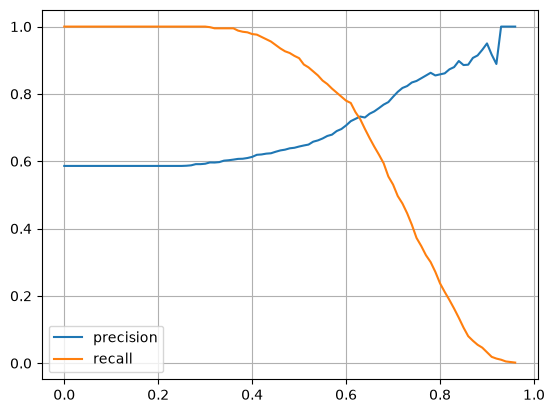

In [48]:
thresholds = np.arange(0, 1, 0.01)
precision = []
recall = []
for t in thresholds:
    converted_prediction = (y_pred > t).astype(int)
    true = (y_val == 1)
    false = (y_val == 0)
    positive = (converted_prediction == 1)
    negative = (converted_prediction == 0)

    tp = (true & positive).sum()
    fp = (false & positive).sum()
    tn = (false & negative).sum()
    fn = (true & negative).sum()

    
    precision_score = tp/(tp+fp) if (tp + fp) > 0 else 0
    recall_score = tp/(tp+fn) if (tp+fn) > 0 else 0
    if precision_score != 0 and recall_score != 0:
        precision.append(precision_score)
        recall.append(recall_score)
    else:
        thresholds = thresholds[thresholds != t]

precision = np.array(precision)
recall = np.array(recall)


idx = np.argmin(np.abs(precision - recall))
best_threshold = thresholds[idx]

print(f"Threshold: {best_threshold:.2f}")
print(f"Precision: {precision[idx]:.3f}")
print(f"Recall: {recall[idx]:.3f}")

plt.plot(thresholds, precision, label = "precision")
plt.plot(thresholds, recall, label = "recall")
plt.legend()
plt.grid()
plt.show()



0.41000000000000003


/tmp/ipykernel_42301/1339814046.py:17: RuntimeWarning: invalid value encountered in scalar divide
  precision_score = tp/(tp+fp)


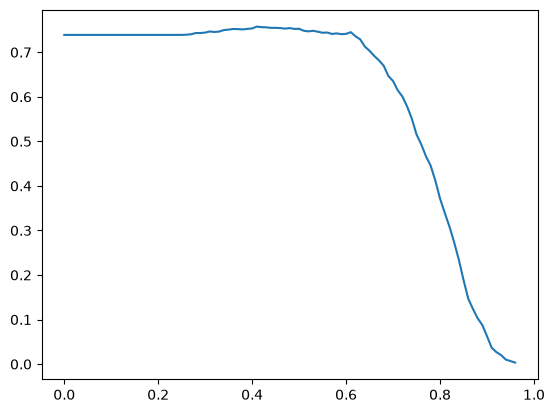

In [49]:
thresholds = np.arange(0, 1, 0.01)
f1 = []

for t in thresholds:
    converted_prediction = (y_pred > t).astype(int)
    true = (y_val == 1)
    false = (y_val == 0)
    positive = (converted_prediction == 1)
    negative = (converted_prediction == 0)

    tp = (true & positive).sum()
    fp = (false & positive).sum()
    tn = (false & negative).sum()
    fn = (true & negative).sum()

    
    precision_score = tp/(tp+fp) 
    recall_score = tp/(tp+fn) 
    if precision_score != 0 and recall_score != 0:
        f1.append((2 * precision_score * recall_score) / (precision_score + recall_score))
    else:
        thresholds = thresholds[thresholds != t]

f1 = np.array(f1)
max = np.argmax(f1)
print(thresholds[max])

plt.plot(thresholds, f1)


In [50]:
from sklearn.model_selection import KFold

scores = []
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for train_idx, val_idx in kfold.split(df_full_train):
    train_df = df_full_train.iloc[train_idx]
    val_df = df_full_train.iloc[val_idx]

    y_train = train_df["converted"].values
    y_val = val_df["converted"].values

    dv, model = train(train_df, y_train)

    y_pred = predict(dv, model, val_df)
    scores.append(roc_auc_score(y_val, y_pred))

print(np.mean(scores))
print(np.std(scores))


0.7317269710972524
0.006853233151022138


In [51]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in [0.000001, 0.001, 1]:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        train_df = df_full_train.iloc[train_idx]
        val_df = df_full_train.iloc[val_idx]

        y_train = train_df["converted"].values
        y_val = val_df["converted"].values

        dv, model = train(train_df, y_train, C = C)

        y_pred = predict(dv, model, val_df)
        scores.append(roc_auc_score(y_val, y_pred))
    print(f"{C} mean - {np.mean(scores)}")


1e-06 mean - 0.6167342250714795
0.001 mean - 0.7491721776030379
1 mean - 0.7317269710972524
